# Microproyecto 2: generación de código Python con Transformers

## 1. Portada e introducción

**Curso:** Modelos Avanzados de Procesamiento de Lenguaje Natural (MAIA) · **Equipo:** MP1 Equipo 21 · **Dataset:** `codeparrot/codeparrot-clean`

Se entrena y compara la capacidad de cinco modelos para completar código Python. Todos usan el tokenizador de SmolLM2 (49.152 tokens) y un contexto de 256 tokens, por lo que sus perplejidades son comparables.

| # | Configuración | Entrenamiento |
|---|---|---|
| 1 | GPT desde cero (decoder-only, PyTorch) | 3 épocas |
| 2 | SmolLM2-135M pre-entrenado | ninguno (baseline) |
| 3 | SmolLM2-135M finetuned | finetuning completo, 1 época |
| 4 | SmolLM2-360M pre-entrenado | ninguno (baseline) |
| 5 | SmolLM2-360M finetuned | finetuning completo, 1 época |

Métricas sobre los 800 archivos de prueba: perplejidad (principal) y validez sintáctica con `ast.parse` sobre 200 prompts (secundaria), más curvas de pérdida y tres ejemplos de generación por modelo entrenado.

**Ejecución.** Google Colab con GPU T4, *Run All*. Si los checkpoints ya están en `checkpoints/`, se cargan en lugar de reentrenar (`REENTRENAR = False`).

## 2. Librerías

Instalación de lo que falte, importaciones, semillas, dispositivo y constantes del proyecto. Precisión mixta: fp16 con `GradScaler` en la T4 y bf16 en GPUs Ampere o superiores. Interruptores: `REENTRENAR`, `USAR_DRIVE` y la variable `MAPLN_SMOKE=1` (prueba rápida).

In [1]:
import os
import sys
import subprocess
import importlib.util

EN_COLAB = 'google.colab' in sys.modules
SALTAR_PIP = os.environ.get('MAPLN_SKIP_PIP') == '1'

if EN_COLAB:
    paquetes = [p for p in ('datasets',) if importlib.util.find_spec(p) is None]
else:
    paquetes = ['torch>=2.3', 'transformers>=4.44', 'datasets>=2.20', 'numpy', 'pandas', 'matplotlib']

if SALTAR_PIP:
    print('MAPLN_SKIP_PIP=1: no se instala ningún paquete.')
elif not paquetes:
    print('No falta ningún paquete.')
else:
    resultado = subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '-q', '--disable-pip-version-check', *paquetes],
        capture_output=True, text=True)
    print(resultado.stdout[-1500:])
    if resultado.returncode != 0:
        raise RuntimeError('Falló la instalación con pip:\n' + resultado.stderr[-1500:])
    print('Instalado:', ', '.join(paquetes))

No falta ningún paquete.


In [2]:
import os
import sys
import ast
import gc
import json
import math
import time
import random
import warnings
import itertools
import contextlib
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
import transformers
import datasets
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, get_cosine_schedule_with_warmup
from IPython.display import display, Markdown

transformers.logging.set_verbosity_error()
EN_COLAB = 'google.colab' in sys.modules


def fijar_semillas(semilla):
    """Deja todos los generadores aleatorios en el mismo punto de partida."""
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(semilla)


if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

# Precisión mixta solo en CUDA. bf16 exige capacidad >= 8.0; la T4 (7.5) usa fp16 + GradScaler.
USAR_AMP = DEVICE.type == 'cuda'
if USAR_AMP and torch.cuda.get_device_capability()[0] >= 8:
    AMP_DTYPE = torch.bfloat16
else:
    AMP_DTYPE = torch.float16
USAR_SCALER = USAR_AMP and AMP_DTYPE == torch.float16


def contexto_amp(activo=True):
    """Bloque de precisión mixta. Fuera de CUDA, o con activo=False, no hace nada (todo en fp32)."""
    if USAR_AMP and activo:
        return torch.autocast(device_type='cuda', dtype=AMP_DTYPE)
    return contextlib.nullcontext()


def liberar_gpu():
    """Recolecta basura y devuelve a la GPU la memoria que quedó libre."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


print('Python       :', sys.version.split()[0])
print('torch        :', torch.__version__)
print('transformers :', transformers.__version__)
print('datasets     :', datasets.__version__)
print('numpy        :', np.__version__)
print('pandas       :', pd.__version__)
print('matplotlib   :', matplotlib.__version__)
print('Dispositivo  :', DEVICE)
if DEVICE.type == 'cuda':
    propiedades = torch.cuda.get_device_properties(0)
    print(f'GPU          : {propiedades.name} ({propiedades.total_memory / 1e9:.1f} GB, '
          f'capacidad {propiedades.major}.{propiedades.minor})')
precision = 'fp32 (sin precisión mixta)' if not USAR_AMP else str(AMP_DTYPE).replace('torch.', '')
print('Precisión    :', precision, '+ GradScaler' if USAR_SCALER else '')

Python       : 3.13.16
torch        : 2.11.0+cu130
transformers : 5.21.0
datasets     : 4.8.5
numpy        : 2.1.3
pandas       : 2.2.3
matplotlib   : 3.10.0
Dispositivo  : cuda
GPU          : Tesla T4 (15.6 GB, capacidad 7.5)
Precisión    : float16 + GradScaler


In [3]:
SEMILLA = 42

# Datos (límites obligatorios de la pauta)
DATASET = 'codeparrot/codeparrot-clean'
MIN_CHARS, MAX_CHARS = 1000, 2000
N_EJEMPLOS = 8000
N_TRAIN, N_VAL, N_TEST = 6400, 800, 800
CONTEXTO = 256
N_EXPLORACION = 5000

# Modelos pre-entrenados obligatorios (comparten tokenizador)
MODELOS_HF = {'135M': 'HuggingFaceTB/SmolLM2-135M', '360M': 'HuggingFaceTB/SmolLM2-360M'}

# GPT desde cero
GPT_CFG = dict(vocab=49152, contexto=CONTEXTO, d_modelo=384, n_cabezas=6, n_capas=6, dropout=0.1)
GPT_ENTRENO = dict(lr=3e-4, wd=0.1, betas=(0.9, 0.95), epocas=3, micro_batch=16, grad_accum=1)

# Finetuning completo: batch efectivo de 16 en ambos, como en el anexo
FT_ENTRENO = {
    '135M': dict(lr=5e-5, wd=0.01, betas=(0.9, 0.999), epocas=1, micro_batch=4, grad_accum=4),
    '360M': dict(lr=3e-5, wd=0.01, betas=(0.9, 0.999), epocas=1, micro_batch=2, grad_accum=8),
}

WARMUP = 0.05
CLIP = 1.0
EVALS_POR_EPOCA = 4
LOTE_EVAL = 8

# Validez sintáctica y generación
N_VALIDEZ = 200
PROMPT_TOKENS = 64
NUEVOS_TOKENS = 128
NUEVOS_EJEMPLO = 120
TEMPERATURA = 0.8
TOP_K = 50
LOTE_GEN = 50

# Interruptores
REENTRENAR = False
USAR_DRIVE = False

SMOKE = os.environ.get('MAPLN_SMOKE') == '1'
MAX_PASOS = None
MAX_BLOQUES_EVAL = None
if SMOKE:
    N_EXPLORACION, MAX_PASOS, MAX_BLOQUES_EVAL = 300, 3, 16
    N_VALIDEZ, NUEVOS_TOKENS, NUEVOS_EJEMPLO, LOTE_GEN = 8, 16, 16, 8
    print('*** MODO DE PRUEBA RÁPIDA: 3 actualizaciones por modelo y evaluación sobre 16 bloques ***')

if USAR_DRIVE and EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    RAIZ = '/content/drive/MyDrive/MAPLN_Microproyecto_2'
else:
    RAIZ = '.'
DIR_DATOS = os.path.join(RAIZ, 'datos')
DIR_CKPT = os.path.join(RAIZ, 'checkpoints_smoke' if SMOKE else 'checkpoints')
RUTA_GPT = os.path.join(DIR_CKPT, 'gpt_desde_cero.pt')
CARPETA_FT = {clave: os.path.join(DIR_CKPT, f'smollm2_{clave.lower()}_ft') for clave in MODELOS_HF}
os.makedirs(DIR_DATOS, exist_ok=True)
os.makedirs(DIR_CKPT, exist_ok=True)

fijar_semillas(SEMILLA)
print(f'Semilla {SEMILLA} | {N_EJEMPLOS} archivos de {MIN_CHARS}-{MAX_CHARS} caracteres | '
      f'split {N_TRAIN}/{N_VAL}/{N_TEST} | contexto {CONTEXTO} tokens')
print(f'Checkpoints en: {os.path.abspath(DIR_CKPT)} | reentrenar: {REENTRENAR}')

Semilla 42 | 8000 archivos de 1000-2000 caracteres | split 6400/800/800 | contexto 256 tokens
Checkpoints en: /content/checkpoints | reentrenar: False


## 3. Carga del dataset y exploración

Lectura en modo *streaming* de una muestra cruda de 5.000 archivos de `codeparrot/codeparrot-clean`: campos, distribución de longitudes, licencias y un ejemplo.

In [4]:
stream = load_dataset(DATASET, split='train', streaming=True)

t0 = time.time()
muestra = list(itertools.islice(stream, N_EXPLORACION))
print(f'{len(muestra)} archivos leídos en {time.time() - t0:.0f} s')
print('Campos de cada ejemplo:', list(muestra[0].keys()))
print('\nPrimer ejemplo (sin el código):')
for campo, valor in muestra[0].items():
    if campo != 'content':
        print(f'  {campo:>13}: {valor}')

README.md:   0%|          | 0.00/1.30k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/54 [00:00<?, ?it/s]

5000 archivos leídos en 6 s
Campos de cada ejemplo: ['repo_name', 'path', 'copies', 'size', 'content', 'license', 'hash', 'line_mean', 'line_max', 'alpha_frac', 'autogenerated']

Primer ejemplo (sin el código):
      repo_name: ahmedbodi/AutobahnPython
           path: examples/asyncio/websocket/echo/client_coroutines.py
         copies: 13
           size: 2044
        license: apache-2.0
           hash: 7822061744094950801
      line_mean: 31.4444444444
       line_max: 79
     alpha_frac: 0.6232876712
  autogenerated: False


Caracteres por archivo: mediana 4,658 | p10 1,491 | p90 22,183 | máximo 749,187
Dentro del rango 1000-2000: 19.9% de la muestra


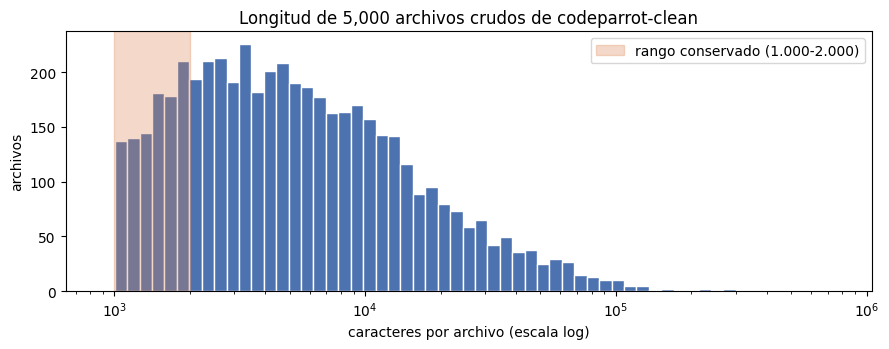

In [5]:
largos = np.array([len(e['content']) for e in muestra])
en_rango = (largos >= MIN_CHARS) & (largos <= MAX_CHARS)

print(f'Caracteres por archivo: mediana {np.median(largos):,.0f} | p10 {np.percentile(largos, 10):,.0f} | '
      f'p90 {np.percentile(largos, 90):,.0f} | máximo {largos.max():,}')
print(f'Dentro del rango {MIN_CHARS}-{MAX_CHARS}: {en_rango.mean():.1%} de la muestra')

fig, ax = plt.subplots(figsize=(9, 3.6))
bordes = np.logspace(np.log10(max(largos.min(), 1)), np.log10(largos.max()), 60)
ax.hist(largos, bins=bordes, color='#4C72B0', edgecolor='white')
ax.axvspan(MIN_CHARS, MAX_CHARS, color='#DD8452', alpha=0.3, label='rango conservado (1.000-2.000)')
ax.set_xscale('log')
ax.set_xlabel('caracteres por archivo (escala log)')
ax.set_ylabel('archivos')
ax.set_title(f'Longitud de {len(muestra):,} archivos crudos de codeparrot-clean')
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
licencias = Counter(e.get('license', 'desconocida') for e in muestra)
print('Licencias más frecuentes en la muestra:')
for licencia, n in licencias.most_common(6):
    print(f'  {licencia:<14} {n / len(muestra):6.1%}')

ejemplo = next(e for e in muestra if MIN_CHARS <= len(e['content']) <= MAX_CHARS)
print(f"\nEjemplo dentro del rango: {ejemplo.get('repo_name', '?')}/{ejemplo.get('path', '?')} "
      f"({len(ejemplo['content'])} caracteres)\n")
print(ejemplo['content'][:700])

Licencias más frecuentes en la muestra:
  apache-2.0      21.3%
  mit             17.8%
  gpl-3.0         17.4%
  bsd-3-clause    17.0%
  agpl-3.0         9.6%
  gpl-2.0          9.4%

Ejemplo dentro del rango: pipet/pipet/pipet/sources/zendesk/tasks.py (1544 caracteres)

from contextlib import contextmanager
from datetime import datetime
from inspect import isclass

from celery import chord, group
from celery_once import QueueOnce
from celery.schedules import crontab
from celery.utils.log import get_task_logger
from sqlalchemy.orm.attributes import flag_modified

# from pipet import celery
from pipet.models import db, Organization
from pipet.sources.zendesk import ZendeskAccount
from pipet.sources.zendesk.models import (
    Base,
    CLASS_REGISTRY,
)


logger = get_task_logger(__name__)


# @celery.task(base=QueueOnce, once={'graceful': True})
def sync(account_id):
    with app.app_context():
        account = ZendeskAccount.query.get(account_id)
        s


## 4. Preprocesamiento

1. **Filtro de longitud** (1.000–2.000 caracteres) sobre el streaming hasta reunir 8.000 archivos, guardados en `datos/corpus_codeparrot.json`.
2. **Tokenización** con el tokenizador de SmolLM2, idéntico en 135M y 360M. Cada archivo termina con `EOS`.
3. **Segmentación** en bloques de 256 tokens, sin relleno. Se aplica en la sección 5, después del split, para que ningún archivo quede repartido entre conjuntos.

In [7]:
RUTA_CORPUS = os.path.join(DIR_DATOS, 'corpus_codeparrot.json')

if os.path.exists(RUTA_CORPUS):
    with open(RUTA_CORPUS, encoding='utf-8') as f:
        guardado = json.load(f)
    corpus, revisados = guardado['corpus'], guardado['revisados']
    print(f'Corpus leído de {RUTA_CORPUS} (caché).')
else:
    t0 = time.time()
    stream = load_dataset(DATASET, split='train', streaming=True)
    corpus, revisados = [], 0
    for ejemplo in stream:
        revisados += 1
        codigo = ejemplo['content']
        if not (MIN_CHARS <= len(codigo) <= MAX_CHARS):
            continue
        corpus.append(codigo)
        if len(corpus) >= N_EJEMPLOS:
            break
    with open(RUTA_CORPUS, 'w', encoding='utf-8') as f:
        json.dump({'revisados': revisados, 'corpus': corpus}, f)
    print(f'Streaming terminado en {time.time() - t0:.0f} s.')

assert len(corpus) == N_EJEMPLOS
assert all(MIN_CHARS <= len(c) <= MAX_CHARS for c in corpus)
print(f'Archivos revisados: {revisados:,} | conservados: {len(corpus):,} ({len(corpus) / revisados:.1%})')

Resolving data files:   0%|          | 0/54 [00:00<?, ?it/s]

Streaming terminado en 22 s.
Archivos revisados: 38,071 | conservados: 8,000 (21.0%)


In [8]:
tokenizer = AutoTokenizer.from_pretrained(MODELOS_HF['135M'])
tokenizer_360 = AutoTokenizer.from_pretrained(MODELOS_HF['360M'])

assert tokenizer.get_vocab() == tokenizer_360.get_vocab(), 'Los dos tokenizadores deberían ser idénticos'
assert tokenizer.vocab_size == GPT_CFG['vocab'] == 49152
EOS_ID = tokenizer.eos_token_id
del tokenizer_360

print('Tamaño del vocabulario (135M = 360M):', tokenizer.vocab_size)
print('Token de fin de texto:', repr(tokenizer.eos_token), '-> id', EOS_ID)

fragmento = 'def suma(a, b):\n    return a + b\n'
ids = tokenizer(fragmento, add_special_tokens=False)['input_ids']
print(f'\n{len(fragmento)} caracteres -> {len(ids)} tokens')
print(tokenizer.convert_ids_to_tokens(ids))

config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

Tamaño del vocabulario (135M = 360M): 49152
Token de fin de texto: '<|endoftext|>' -> id 0

33 caracteres -> 14 tokens
['def', 'Ġsum', 'a', '(', 'a', ',', 'Ġb', '):', 'ĊĠĠĠ', 'Ġreturn', 'Ġa', 'Ġ+', 'Ġb', 'Ċ']


Tokenización: 6.1 s
Tokens por archivo: mediana 421 | mínimo 199 | máximo 1358 | total 3,461,031
Caracteres por token: 3.42
Archivos más largos que una ventana de 256 tokens: 98%


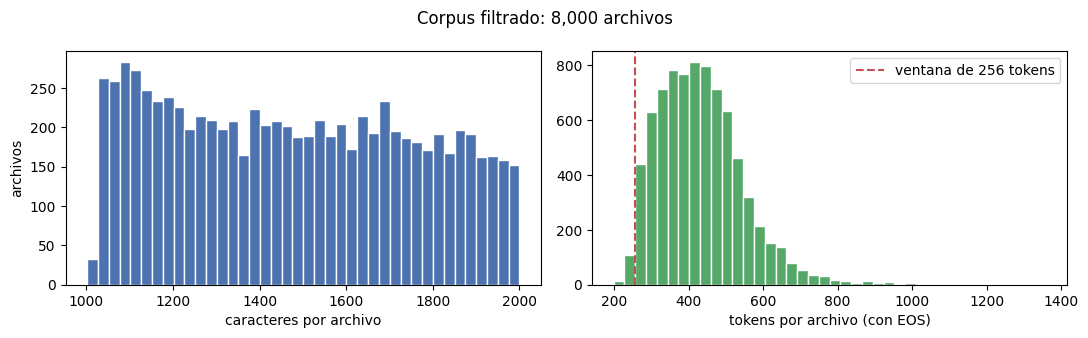

In [9]:
t0 = time.time()
ids_docs = tokenizer(corpus, add_special_tokens=False)['input_ids']
ids_docs = [ids + [EOS_ID] for ids in ids_docs]
n_tokens = np.array([len(ids) for ids in ids_docs])
chars_por_token = sum(len(c) for c in corpus) / (n_tokens.sum() - len(ids_docs))

assert max(max(ids) for ids in ids_docs) < tokenizer.vocab_size
print(f'Tokenización: {time.time() - t0:.1f} s')
print(f'Tokens por archivo: mediana {np.median(n_tokens):.0f} | mínimo {n_tokens.min()} | '
      f'máximo {n_tokens.max()} | total {n_tokens.sum():,}')
print(f'Caracteres por token: {chars_por_token:.2f}')
print(f'Archivos más largos que una ventana de {CONTEXTO} tokens: {(n_tokens > CONTEXTO).mean():.0%}')

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4))
ejes[0].hist([len(c) for c in corpus], bins=40, color='#4C72B0', edgecolor='white')
ejes[0].set_xlabel('caracteres por archivo')
ejes[0].set_ylabel('archivos')
ejes[1].hist(n_tokens, bins=40, color='#55A868', edgecolor='white')
ejes[1].axvline(CONTEXTO, color='#C44E52', ls='--', label=f'ventana de {CONTEXTO} tokens')
ejes[1].set_xlabel('tokens por archivo (con EOS)')
ejes[1].legend()
fig.suptitle(f'Corpus filtrado: {len(corpus):,} archivos')
plt.tight_layout()
plt.show()

In [10]:
def segmentar(lista_ids, contexto=CONTEXTO):
    """Concatena documentos (cada uno ya termina en EOS) y los corta en bloques de `contexto` tokens."""
    flujo = np.fromiter(itertools.chain.from_iterable(lista_ids), dtype=np.int64)
    n_bloques = len(flujo) // contexto
    return torch.from_numpy(flujo[:n_bloques * contexto].reshape(n_bloques, contexto))


demo = segmentar(ids_docs[:3])
total_demo = sum(len(x) for x in ids_docs[:3])
print(f'3 archivos = {total_demo} tokens -> {demo.shape[0]} bloques de {demo.shape[1]} '
      f'(se descartan {total_demo - demo.numel()} tokens del final)')

fila, columna = divmod(len(ids_docs[0]) - 1, CONTEXTO)
print(f'\nEl primer archivo termina en el bloque {fila}, posición {columna}. Texto alrededor del corte:')
print(repr(tokenizer.decode(demo[fila, max(columna - 12, 0):columna + 12].tolist())))

3 archivos = 1112 tokens -> 4 bloques de 256 (se descartan 88 tokens del final)

El primer archivo termina en el bloque 1, posición 140. Texto alrededor del corte:
'query.all()])\n    job.apply_async()\n<|endoftext|>#\n# Copyright 2010 Free Software'


## 5. Split train / validación / prueba

Reparto por archivo completo y con semilla fija: 6.400 / 800 / 800. Validación se usa para monitorear y elegir el mejor checkpoint; prueba solo se usa en la sección 8.

In [11]:
orden = np.random.default_rng(SEMILLA).permutation(N_EJEMPLOS)
idx_train = orden[:N_TRAIN]
idx_val = orden[N_TRAIN:N_TRAIN + N_VAL]
idx_test = orden[N_TRAIN + N_VAL:]

assert (len(idx_train), len(idx_val), len(idx_test)) == (N_TRAIN, N_VAL, N_TEST)
assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test) or set(idx_val) & set(idx_test))

docs_train = [ids_docs[i] for i in idx_train]
docs_val = [ids_docs[i] for i in idx_val]
docs_test = [ids_docs[i] for i in idx_test]
print(f'Archivos: entrenamiento {len(docs_train)} | validación {len(docs_val)} | prueba {len(docs_test)}')

Archivos: entrenamiento 6400 | validación 800 | prueba 800


In [12]:
bloques_train = segmentar(docs_train)
bloques_val = segmentar(docs_val)
bloques_test = segmentar(docs_test)

resumen_split = pd.DataFrame({
    'archivos': [len(docs_train), len(docs_val), len(docs_test)],
    'tokens': [sum(map(len, d)) for d in (docs_train, docs_val, docs_test)],
    'bloques de 256': [len(b) for b in (bloques_train, bloques_val, bloques_test)],
}, index=['entrenamiento', 'validación', 'prueba'])
resumen_split['tokens evaluados (255 por bloque)'] = resumen_split['bloques de 256'] * (CONTEXTO - 1)
display(resumen_split)

,archivos,tokens,bloques de 256,tokens evaluados (255 por bloque)
entrenamiento,6400,2766261,10805,2755275
validación,800,347858,1358,346290
prueba,800,346912,1355,345525


## 6. Modelo desde cero

GPT decoder-only escrito en PyTorch, sin `nn.Transformer`: 6 bloques pre-LN con d = 384, atención causal de 6 cabezas, MLP 384→1536→384, embeddings de posición aprendidos y pesos atados entre embedding y salida (29,6 M de parámetros).

Entrenamiento: AdamW, lr 3e-4, 3 épocas, batch 16, dropout 0,1, weight decay 0,1, calentamiento y decaimiento coseno, recorte de gradiente 1,0 y validación 4 veces por época. `entrenar()` es el mismo bucle que usan los finetunings y deja el modelo con los pesos del mejor paso de validación.

In [13]:
class AtencionCausalMultiCabeza(nn.Module):
    def __init__(self, d_modelo, n_cabezas, contexto, dropout):
        super().__init__()
        assert d_modelo % n_cabezas == 0
        self.n_cabezas = n_cabezas
        self.d_cabeza = d_modelo // n_cabezas
        self.qkv = nn.Linear(d_modelo, 3 * d_modelo)
        self.proyeccion = nn.Linear(d_modelo, d_modelo)
        self.drop_atencion = nn.Dropout(dropout)
        self.drop_salida = nn.Dropout(dropout)
        mascara = torch.tril(torch.ones(contexto, contexto, dtype=torch.bool))
        self.register_buffer('mascara', mascara.view(1, 1, contexto, contexto), persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_cabezas, self.d_cabeza).transpose(1, 2)
        k = k.view(B, T, self.n_cabezas, self.d_cabeza).transpose(1, 2)
        v = v.view(B, T, self.n_cabezas, self.d_cabeza).transpose(1, 2)

        puntajes = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_cabeza)
        puntajes = puntajes.masked_fill(~self.mascara[:, :, :T, :T], float('-inf'))
        pesos = self.drop_atencion(F.softmax(puntajes, dim=-1))
        y = pesos @ v

        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.drop_salida(self.proyeccion(y))

In [14]:
class MLP(nn.Module):
    def __init__(self, d_modelo, dropout):
        super().__init__()
        self.entrada = nn.Linear(d_modelo, 4 * d_modelo)
        self.salida = nn.Linear(4 * d_modelo, d_modelo)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(self.salida(F.gelu(self.entrada(x))))


class BloqueTransformer(nn.Module):
    """Pre-LN: se normaliza antes de cada subcapa y su salida se suma al residual."""
    def __init__(self, d_modelo, n_cabezas, contexto, dropout):
        super().__init__()
        self.ln_atencion = nn.LayerNorm(d_modelo)
        self.atencion = AtencionCausalMultiCabeza(d_modelo, n_cabezas, contexto, dropout)
        self.ln_mlp = nn.LayerNorm(d_modelo)
        self.mlp = MLP(d_modelo, dropout)

    def forward(self, x):
        x = x + self.atencion(self.ln_atencion(x))
        x = x + self.mlp(self.ln_mlp(x))
        return x

In [15]:
class GPTDesdeCero(nn.Module):
    def __init__(self, vocab, contexto, d_modelo, n_cabezas, n_capas, dropout):
        super().__init__()
        self.contexto = contexto
        self.emb_tokens = nn.Embedding(vocab, d_modelo)
        self.emb_posicion = nn.Embedding(contexto, d_modelo)
        self.drop = nn.Dropout(dropout)
        self.bloques = nn.ModuleList(
            [BloqueTransformer(d_modelo, n_cabezas, contexto, dropout) for _ in range(n_capas)])
        self.ln_final = nn.LayerNorm(d_modelo)
        self.cabeza = nn.Linear(d_modelo, vocab, bias=False)
        self.cabeza.weight = self.emb_tokens.weight

        self.apply(self._iniciar_pesos)
        for nombre, p in self.named_parameters():
            if nombre.endswith('proyeccion.weight') or nombre.endswith('salida.weight'):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_capas))

    @staticmethod
    def _iniciar_pesos(modulo):
        if isinstance(modulo, nn.Linear):
            nn.init.normal_(modulo.weight, mean=0.0, std=0.02)
            if modulo.bias is not None:
                nn.init.zeros_(modulo.bias)
        elif isinstance(modulo, nn.Embedding):
            nn.init.normal_(modulo.weight, mean=0.0, std=0.02)

    def forward(self, ids):
        B, T = ids.shape
        assert T <= self.contexto, f'La secuencia ({T}) supera el contexto ({self.contexto})'
        posiciones = torch.arange(T, device=ids.device)
        x = self.drop(self.emb_tokens(ids) + self.emb_posicion(posiciones))
        for bloque in self.bloques:
            x = bloque(x)
        return self.cabeza(self.ln_final(x))

In [16]:
def logits_de(modelo, x):
    """Logits (B, T, V) de cualquiera de los cinco modelos."""
    salida = modelo(x)
    return salida if torch.is_tensor(salida) else salida.logits


def nll_por_token(logits, x):
    """Suma de -log p(x_i | x_<i) en el lote y cuántos tokens se predijeron."""
    prediccion = logits[:, :-1, :].float()
    objetivo = x[:, 1:]
    suma = F.cross_entropy(prediccion.reshape(-1, prediccion.size(-1)), objetivo.reshape(-1), reduction='sum')
    return suma, objetivo.numel()


def iterar_lotes(bloques, tam, mezclar=False, generador=None):
    orden = torch.randperm(len(bloques), generator=generador) if mezclar else torch.arange(len(bloques))
    for i in range(0, len(orden), tam):
        yield bloques[orden[i:i + tam]]


@torch.no_grad()
def evaluar_nll(modelo, bloques, usar_amp=True, tam_lote=LOTE_EVAL):
    """NLL promedio por token: se acumulan sumas y conteos y se divide una sola vez al final."""
    modelo.eval()
    if MAX_BLOQUES_EVAL:
        bloques = bloques[:MAX_BLOQUES_EVAL]
    suma, n = 0.0, 0
    for x in iterar_lotes(bloques, tam_lote):
        x = x.to(DEVICE)
        with contexto_amp(usar_amp):
            s, k = nll_por_token(logits_de(modelo, x), x)
        suma += s.item()
        n += k
    return suma / n


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())

In [17]:
fijar_semillas(SEMILLA)
gpt_prueba = GPTDesdeCero(**GPT_CFG).to(DEVICE)
x = bloques_train[:2].to(DEVICE)
with torch.no_grad():
    logits = gpt_prueba(x)
    suma, n = nll_por_token(logits, x)

print('Entrada:', tuple(x.shape), '-> logits:', tuple(logits.shape))
print(f'Parámetros: {contar_parametros(gpt_prueba):,} '
      f'(de ellos {gpt_prueba.emb_tokens.weight.numel():,} en el embedding compartido con la salida)')
print(f'Pérdida inicial: {(suma / n).item():.3f} nats | ln({GPT_CFG["vocab"]}) = {math.log(GPT_CFG["vocab"]):.3f}')
del gpt_prueba, logits, x
liberar_gpu()

Entrada: (2, 256) -> logits: (2, 256, 49152)
Parámetros: 29,620,224 (de ellos 18,874,368 en el embedding compartido con la salida)
Pérdida inicial: 10.834 nats | ln(49152) = 10.803


In [18]:
def entrenar(modelo, nombre, lr, wd, betas, epocas, micro_batch, grad_accum):
    """Bucle común de entrenamiento: deja en `modelo` los pesos del mejor paso de validación y devuelve la historia."""
    modelo.to(DEVICE)
    con_decay = [p for p in modelo.parameters() if p.requires_grad and p.dim() >= 2]
    sin_decay = [p for p in modelo.parameters() if p.requires_grad and p.dim() < 2]
    optimizador = torch.optim.AdamW([{'params': con_decay, 'weight_decay': wd},
                                     {'params': sin_decay, 'weight_decay': 0.0}], lr=lr, betas=betas)

    pasos_por_epoca = (len(bloques_train) // micro_batch) // grad_accum
    pasos_totales = pasos_por_epoca * epocas
    if MAX_PASOS:
        pasos_totales = min(pasos_totales, MAX_PASOS)
    planificador = get_cosine_schedule_with_warmup(optimizador, max(1, int(WARMUP * pasos_totales)), pasos_totales)
    escalador = torch.amp.GradScaler('cuda', enabled=USAR_SCALER)
    cada = max(1, pasos_por_epoca // EVALS_POR_EPOCA)
    generador = torch.Generator().manual_seed(SEMILLA)

    historia = dict(nombre=nombre, batch_efectivo=micro_batch * grad_accum,
                    pasos=[0], train=[None], val=[evaluar_nll(modelo, bloques_val)], lr=[0.0])
    print(f'--- {nombre} | {contar_parametros(modelo) / 1e6:.1f} M parámetros | {pasos_totales} actualizaciones '
          f'(micro-batch {micro_batch} x acumulación {grad_accum}) ---')
    print(f'paso     0 | val {historia["val"][0]:.4f} (punto de partida)')

    mejor_val, mejor_paso, mejor_estado = float('inf'), 0, None
    suma_tr, tokens_tr, descartados, paso = 0.0, 0, 0, 0
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    modelo.train()
    optimizador.zero_grad(set_to_none=True)

    for epoca in range(epocas):
        for i, x in enumerate(iterar_lotes(bloques_train, micro_batch, mezclar=True, generador=generador)):
            if i >= pasos_por_epoca * grad_accum or paso >= pasos_totales:
                break
            x = x.to(DEVICE)
            with contexto_amp():
                suma, n = nll_por_token(logits_de(modelo, x), x)
            if torch.isfinite(suma):
                # se divide por grad_accum para que el gradiente acumulado equivalga al de un lote grande
                escalador.scale(suma / n / grad_accum).backward()
                suma_tr += suma.item()
                tokens_tr += n
            else:
                descartados += 1

            if (i + 1) % grad_accum == 0:
                escalador.unscale_(optimizador)
                nn.utils.clip_grad_norm_(modelo.parameters(), CLIP)
                escalador.step(optimizador)
                escalador.update()
                optimizador.zero_grad(set_to_none=True)
                planificador.step()
                paso += 1

                if paso % cada == 0 or paso == pasos_totales:
                    val = evaluar_nll(modelo, bloques_val)
                    modelo.train()
                    historia['pasos'].append(paso)
                    historia['train'].append(suma_tr / max(tokens_tr, 1))
                    historia['val'].append(val)
                    historia['lr'].append(planificador.get_last_lr()[0])
                    marca = ''
                    if val < mejor_val:
                        mejor_val, mejor_paso = val, paso
                        mejor_estado = {k: v.detach().to('cpu', copy=True) for k, v in modelo.state_dict().items()}
                        marca = '  <- mejor'
                    print(f'paso {paso:5d} | época {epoca + 1} | train {historia["train"][-1]:.4f} | val {val:.4f} '
                          f'| lr {historia["lr"][-1]:.1e} | {time.time() - t0:5.0f} s{marca}')
                    suma_tr, tokens_tr = 0.0, 0

    modelo.load_state_dict(mejor_estado)
    memoria = torch.cuda.max_memory_allocated() / 1e9 if torch.cuda.is_available() else None
    historia.update(mejor_paso=mejor_paso, mejor_val=mejor_val, segundos=time.time() - t0,
                    descartados=descartados, memoria_max_gb=memoria)
    print(f'Mejor paso: {mejor_paso} (val {mejor_val:.4f}, PPL {math.exp(mejor_val):.2f}) | '
          f'{historia["segundos"] / 60:.1f} min'
          + (f' | memoria máxima {memoria:.1f} GB' if memoria else '')
          + (f' | lotes descartados por desborde: {descartados}' if descartados else ''))
    return historia


def a_float(valores):
    return np.array([np.nan if v is None else v for v in valores], dtype=float)


def graficar_historia(historia, ax, titulo=None):
    """Curvas de entrenamiento y validación contra millones de tokens vistos."""
    escala = historia['batch_efectivo'] * (CONTEXTO - 1) / 1e6
    tokens = np.array(historia['pasos']) * escala
    ax.plot(tokens, a_float(historia['train']), 'o-', color='#4C72B0', label='entrenamiento')
    ax.plot(tokens, a_float(historia['val']), 's-', color='#DD8452', label='validación')
    ax.axvline(historia['mejor_paso'] * escala, color='gray', ls=':', label=f'mejor paso ({historia["mejor_paso"]})')
    ax.set_xlabel('millones de tokens vistos')
    ax.set_ylabel('NLL por token (nats)')
    ax.set_title(titulo or historia['nombre'])
    ax.grid(alpha=0.3)
    ax.legend()

--- GPT desde cero | 29.6 M parámetros | 2025 actualizaciones (micro-batch 16 x acumulación 1) ---
paso     0 | val 10.8564 (punto de partida)
paso   168 | época 1 | train 7.3674 | val 5.4039 | lr 3.0e-04 |    24 s  <- mejor
paso   336 | época 1 | train 5.0283 | val 4.7224 | lr 2.9e-04 |    47 s  <- mejor
paso   504 | época 1 | train 4.5724 | val 4.3586 | lr 2.7e-04 |    71 s  <- mejor
paso   672 | época 1 | train 4.2803 | val 4.1223 | lr 2.4e-04 |    94 s  <- mejor
paso   840 | época 2 | train 3.9760 | val 3.9676 | lr 2.0e-04 |   119 s  <- mejor
paso  1008 | época 2 | train 3.9004 | val 3.8482 | lr 1.6e-04 |   143 s  <- mejor
paso  1176 | época 2 | train 3.7995 | val 3.7486 | lr 1.2e-04 |   169 s  <- mejor
paso  1344 | época 2 | train 3.6890 | val 3.6792 | lr 8.4e-05 |   193 s  <- mejor
paso  1512 | época 3 | train 3.5382 | val 3.6344 | lr 5.0e-05 |   218 s  <- mejor
paso  1680 | época 3 | train 3.5133 | val 3.6036 | lr 2.3e-05 |   243 s  <- mejor
paso  1848 | época 3 | train 3.5534 |

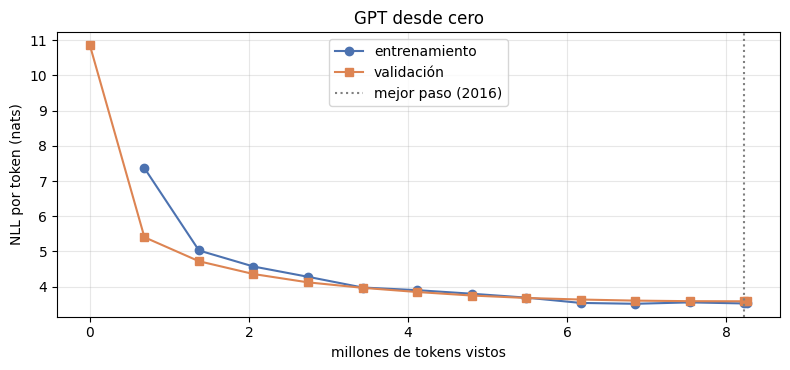

In [19]:
if os.path.exists(RUTA_GPT) and not REENTRENAR:
    historia_gpt = torch.load(RUTA_GPT, map_location='cpu')['historia']
    print(f'Checkpoint encontrado en {RUTA_GPT}: se reutiliza '
          f'(mejor paso {historia_gpt["mejor_paso"]}, val {historia_gpt["mejor_val"]:.4f}).')
else:
    fijar_semillas(SEMILLA)
    gpt = GPTDesdeCero(**GPT_CFG)
    historia_gpt = entrenar(gpt, 'GPT desde cero', **GPT_ENTRENO)
    torch.save({'config': GPT_CFG,
                'estado': {k: v.cpu() for k, v in gpt.state_dict().items()},
                'historia': historia_gpt}, RUTA_GPT)
    print('Checkpoint guardado en', RUTA_GPT)
    del gpt
    liberar_gpu()

fig, ax = plt.subplots(figsize=(8, 3.8))
graficar_historia(historia_gpt, ax)
plt.tight_layout()
plt.show()

## 7. Finetuning de los modelos pre-entrenados

Finetuning **completo** (todos los parámetros, sin LoRA) de SmolLM2-135M y SmolLM2-360M, de a uno y liberando la GPU entre modelos. Técnicas del anexo para reducir memoria:

- **Precisión mixta:** `contexto_amp()` y `GradScaler` en `entrenar()`.
- **Acumulación de gradiente:** `grad_accum` en `entrenar()`, con batch efectivo de 16.
- **Gradient checkpointing:** `gradient_checkpointing_enable()` y `use_cache = False` en `finetunear()`.

| Modelo | lr (AdamW) | Épocas | Micro-batch × acumulación |
|---|---|---|---|
| SmolLM2-135M | 5e-5 | 1 | 4 × 4 |
| SmolLM2-360M | 3e-5 | 1 | 2 × 8 |

El paso 0 de cada curva es la validación del modelo pre-entrenado (baseline). Los checkpoints se guardan con `save_pretrained`.

In [20]:
for clave, nombre in MODELOS_HF.items():
    modelo = AutoModelForCausalLM.from_pretrained(nombre)
    cfg = modelo.config
    print(nombre)
    print('  Tamaño del vocabulario:', cfg.vocab_size)
    print(f'  Parámetros: {contar_parametros(modelo):,}')
    print(f'  Capas: {cfg.num_hidden_layers} | dimensión oculta: {cfg.hidden_size} | '
          f'cabezas de atención: {cfg.num_attention_heads} | contexto máximo: {cfg.max_position_embeddings}')
    assert cfg.vocab_size == tokenizer.vocab_size == GPT_CFG['vocab']
    del modelo
liberar_gpu()
print(f'\nComparación: el GPT desde cero tiene {GPT_CFG["n_capas"]} capas y dimensión {GPT_CFG["d_modelo"]}.')

model.safetensors: reconstructing file:   0%|          |  0.00B /  269MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

HuggingFaceTB/SmolLM2-135M
  Tamaño del vocabulario: 49152
  Parámetros: 134,515,008
  Capas: 30 | dimensión oculta: 576 | cabezas de atención: 9 | contexto máximo: 8192


model.safetensors: reconstructing file:   0%|          |  0.00B /  724MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

HuggingFaceTB/SmolLM2-360M
  Tamaño del vocabulario: 49152
  Parámetros: 361,821,120
  Capas: 32 | dimensión oculta: 960 | cabezas de atención: 15 | contexto máximo: 8192

Comparación: el GPT desde cero tiene 6 capas y dimensión 384.


In [21]:
def finetunear(clave):
    carpeta = CARPETA_FT[clave]
    ruta_historia = os.path.join(carpeta, 'historia.json')
    if os.path.exists(ruta_historia) and not REENTRENAR:
        with open(ruta_historia, encoding='utf-8') as f:
            historia = json.load(f)
        print(f'Checkpoint encontrado en {carpeta}: se reutiliza '
              f'(mejor paso {historia["mejor_paso"]}, val {historia["mejor_val"]:.4f}).')
        return historia

    fijar_semillas(SEMILLA)
    modelo = AutoModelForCausalLM.from_pretrained(MODELOS_HF[clave]).float()
    modelo.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
    modelo.config.use_cache = False

    historia = entrenar(modelo, f'SmolLM2-{clave} finetuned', **FT_ENTRENO[clave])

    modelo.config.use_cache = True
    modelo.save_pretrained(carpeta)
    tokenizer.save_pretrained(carpeta)
    with open(ruta_historia, 'w', encoding='utf-8') as f:
        json.dump(historia, f)
    print('Checkpoint guardado en', carpeta)
    del modelo
    liberar_gpu()
    return historia

In [22]:
historia_135 = finetunear('135M')

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

--- SmolLM2-135M finetuned | 134.5 M parámetros | 675 actualizaciones (micro-batch 4 x acumulación 4) ---
paso     0 | val 1.7853 (punto de partida)
paso   168 | época 1 | train 1.6852 | val 1.6810 | lr 4.5e-05 |   206 s  <- mejor
paso   336 | época 1 | train 1.6345 | val 1.6465 | lr 2.7e-05 |   412 s  <- mejor
paso   504 | época 1 | train 1.6171 | val 1.6312 | lr 8.3e-06 |   618 s  <- mejor
paso   672 | época 1 | train 1.5983 | val 1.6279 | lr 2.7e-09 |   823 s  <- mejor
paso   675 | época 1 | train 1.4029 | val 1.6279 | lr 0.0e+00 |   847 s
Mejor paso: 672 (val 1.6279, PPL 5.09) | 14.1 min | memoria máxima 3.1 GB


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Checkpoint guardado en ./checkpoints/smollm2_135m_ft


In [23]:
historia_360 = finetunear('360M')

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

--- SmolLM2-360M finetuned | 361.8 M parámetros | 675 actualizaciones (micro-batch 2 x acumulación 8) ---
paso     0 | val 1.5217 (punto de partida)
paso   168 | época 1 | train 1.4382 | val 1.4460 | lr 2.7e-05 |   436 s  <- mejor
paso   336 | época 1 | train 1.4076 | val 1.4216 | lr 1.6e-05 |   871 s  <- mejor
paso   504 | época 1 | train 1.3918 | val 1.4115 | lr 5.0e-06 |  1307 s  <- mejor
paso   672 | época 1 | train 1.3808 | val 1.4095 | lr 1.6e-09 |  1739 s  <- mejor
paso   675 | época 1 | train 1.2023 | val 1.4095 | lr 0.0e+00 |  1787 s
Mejor paso: 672 (val 1.4095, PPL 4.09) | 29.8 min | memoria máxima 7.3 GB | lotes descartados por desborde: 1


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Checkpoint guardado en ./checkpoints/smollm2_360m_ft


In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, h in zip(ejes, (historia_135, historia_360)):
    graficar_historia(h, ax)
    ax.axhline(h['val'][0], color='#55A868', ls='--', label='baseline (sin finetuning)')
    ax.legend()
plt.tight_layout()
plt.show()

for h in (historia_135, historia_360):
    print(f'{h["nombre"]}: val {h["val"][0]:.4f} -> {h["mejor_val"]:.4f} '
          f'(PPL {math.exp(h["val"][0]):.2f} -> {math.exp(h["mejor_val"]):.2f}) | {h["segundos"] / 60:.1f} min'
          + (f' | memoria máxima {h["memoria_max_gb"]:.1f} GB' if h.get('memoria_max_gb') else ''))

## 8. Evaluación y comparación

Las cinco configuraciones se evalúan sobre los mismos 800 archivos de prueba.

- **Perplejidad:** $\text{PPL} = \exp\left(-\frac{1}{N}\sum_{i=1}^{N}\log p(x_i \mid x_{<i})\right)$. Se acumula $-\log p$ sobre todos los tokens y se divide una sola vez por $N$, sin relleno y en fp32.
- **Validez sintáctica:** 200 prompts de 64 tokens (semilla fija), hasta 128 tokens generados con `generar()` (temperatura 0,8, top-k 50) y `ast.parse` sin ejecutar el código. Si la generación se corta por el límite de tokens, se descarta la última línea. Se reporta con intervalo de Wilson al 95 % y se compara con la referencia del código real.

In [25]:
CONFIGURACIONES = {
    'GPT desde cero': RUTA_GPT,
    'SmolLM2-135M pre-entrenado': MODELOS_HF['135M'],
    'SmolLM2-135M finetuned': CARPETA_FT['135M'],
    'SmolLM2-360M pre-entrenado': MODELOS_HF['360M'],
    'SmolLM2-360M finetuned': CARPETA_FT['360M'],
}
ENTRENADOS = ['GPT desde cero', 'SmolLM2-135M finetuned', 'SmolLM2-360M finetuned']


def cargar_configuracion(nombre):
    """Carga una de las cinco configuraciones en el dispositivo, en fp32 y en modo evaluación."""
    ruta = CONFIGURACIONES[nombre]
    if ruta == RUTA_GPT:
        checkpoint = torch.load(ruta, map_location='cpu')
        modelo = GPTDesdeCero(**checkpoint['config'])
        modelo.load_state_dict(checkpoint['estado'])
    else:
        modelo = AutoModelForCausalLM.from_pretrained(ruta).float()
        modelo.config.use_cache = False
    return modelo.to(DEVICE).eval()


def perplejidad(modelo, bloques):
    """Devuelve (NLL promedio por token, PPL), calculadas en fp32 sobre todos los tokens."""
    nll = evaluar_nll(modelo, bloques, usar_amp=False)
    return nll, math.exp(nll)

In [26]:
@torch.no_grad()
def generar(modelo, prompts, max_nuevos, temperatura=TEMPERATURA, top_k=TOP_K, semilla=SEMILLA):
    """Bucle autorregresivo escrito a mano: devuelve, por secuencia, (tokens nuevos sin el EOS, si cerró con EOS)."""
    modelo.eval()
    azar = torch.Generator().manual_seed(semilla)
    ids = prompts.to(DEVICE)
    terminado = torch.zeros(len(ids), dtype=torch.bool)
    nuevos = []
    for _ in range(max_nuevos):
        ventana = ids[:, -CONTEXTO:]
        with contexto_amp():
            logits = logits_de(modelo, ventana)[:, -1, :]
        logits = logits.float().cpu()
        if temperatura == 0:
            siguiente = logits.argmax(dim=-1)
        else:
            logits = logits / temperatura
            if top_k:
                umbral = torch.topk(logits, top_k, dim=-1).values[:, -1:]
                logits = logits.masked_fill(logits < umbral, float('-inf'))
            probabilidades = F.softmax(logits, dim=-1)
            siguiente = torch.multinomial(probabilidades, 1, generator=azar).squeeze(1)
        siguiente[terminado] = EOS_ID
        terminado |= siguiente == EOS_ID
        nuevos.append(siguiente)
        ids = torch.cat([ids, siguiente.unsqueeze(1).to(DEVICE)], dim=1)
        if terminado.all():
            break

    salidas = []
    for fila in torch.stack(nuevos, dim=1).tolist():
        if EOS_ID in fila:
            salidas.append((fila[:fila.index(EOS_ID)], True))
        else:
            salidas.append((fila, False))
    return salidas


def es_valido(codigo, termino_en_eos):
    """(True, None) si ast.parse acepta el código, sin ejecutarlo; si se cortó por el límite de tokens, antes se descarta su última línea."""
    if not termino_en_eos:
        codigo = codigo.rsplit('\n', 1)[0]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            ast.parse(codigo)
        return True, None
    except SyntaxError as error:
        return False, error.msg
    except (ValueError, RecursionError, MemoryError) as error:
        return False, type(error).__name__


def intervalo_wilson(aciertos, n, z=1.96):
    """Intervalo de confianza del 95 % para una proporción; se comporta bien con n pequeño."""
    p = aciertos / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margen, centro + margen

In [27]:
elegidos = np.random.default_rng(SEMILLA).choice(len(docs_test), size=N_VALIDEZ, replace=False)
assert all(len(docs_test[i]) > PROMPT_TOKENS for i in elegidos)
PROMPTS_VALIDEZ = torch.tensor([docs_test[i][:PROMPT_TOKENS] for i in elegidos])


def validez_sintactica(salidas):
    """Une prompt y continuación, decodifica y revisa cada texto con ast.parse."""
    filas = []
    for prompt, (nuevos, cerro) in zip(PROMPTS_VALIDEZ.tolist(), salidas):
        texto = tokenizer.decode(prompt + nuevos)
        valido, motivo = es_valido(texto, cerro)
        filas.append(dict(texto=texto, valido=valido, motivo=motivo, cerro=cerro))
    return filas


continuaciones_reales = []
for i in elegidos:
    real = docs_test[i][PROMPT_TOKENS:PROMPT_TOKENS + NUEVOS_TOKENS]
    if EOS_ID in real:
        continuaciones_reales.append((real[:real.index(EOS_ID)], True))
    else:
        continuaciones_reales.append((real, False))
filas_ref = validez_sintactica(continuaciones_reales)
k_ref = sum(f['valido'] for f in filas_ref)
print(f'{N_VALIDEZ} prompts de {PROMPT_TOKENS} tokens tomados de {len(docs_test)} archivos de prueba')
print(f'Referencia (código real): {k_ref}/{N_VALIDEZ} = {k_ref / N_VALIDEZ:.1%} válidos')

200 prompts de 64 tokens tomados de 800 archivos de prueba
Referencia (código real): 114/200 = 57.0% válidos


In [28]:
resultados, filas_validez = {}, {}
for nombre in CONFIGURACIONES:
    t0 = time.time()
    modelo = cargar_configuracion(nombre)
    nll, ppl = perplejidad(modelo, bloques_test)

    salidas = []
    for i in range(0, N_VALIDEZ, LOTE_GEN):
        salidas += generar(modelo, PROMPTS_VALIDEZ[i:i + LOTE_GEN], NUEVOS_TOKENS, semilla=SEMILLA + i)
    filas = validez_sintactica(salidas)
    validos = sum(f['valido'] for f in filas)

    resultados[nombre] = dict(parametros=contar_parametros(modelo), nll=nll, ppl=ppl, validos=validos, n=N_VALIDEZ)
    filas_validez[nombre] = filas
    print(f'{nombre:<28} | NLL {nll:.4f} | PPL {ppl:10.2f} | válidas {validos:3d}/{N_VALIDEZ} | {time.time() - t0:4.0f} s')
    del modelo
    liberar_gpu()

with open(os.path.join(DIR_CKPT, 'resultados_prueba.json'), 'w', encoding='utf-8') as f:
    json.dump(dict(resultados=resultados, referencia=dict(validos=k_ref, n=N_VALIDEZ)), f, indent=2)

GPT desde cero               | NLL 3.5954 | PPL      36.43 | válidas  81/200 |   75 s


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

SmolLM2-135M pre-entrenado   | NLL 1.7945 | PPL       6.02 | válidas 118/200 |  242 s


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

SmolLM2-135M finetuned       | NLL 1.6206 | PPL       5.06 | válidas 127/200 |  245 s


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

SmolLM2-360M pre-entrenado   | NLL 1.5263 | PPL       4.60 | válidas 126/200 |  469 s


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

SmolLM2-360M finetuned       | NLL 1.4017 | PPL       4.06 | válidas 128/200 |  482 s


In [ ]:
HISTORIAS = {'GPT desde cero': historia_gpt,
             'SmolLM2-135M finetuned': historia_135,
             'SmolLM2-360M finetuned': historia_360}

filas_tabla = []
for nombre, r in resultados.items():
    bajo, alto = intervalo_wilson(r['validos'], r['n'])
    historia = HISTORIAS.get(nombre)
    filas_tabla.append({
        'configuración': nombre,
        'parámetros (M)': round(r['parametros'] / 1e6, 1),
        'NLL prueba': round(r['nll'], 4),
        'PPL prueba': round(r['ppl'], 2),
        'válidas (%)': round(100 * r['validos'] / r['n'], 1),
        'IC 95 % (Wilson)': f'{100 * bajo:.1f} - {100 * alto:.1f}',
        'entrenamiento (min)': round(historia['segundos'] / 60, 1) if historia else '-',
    })
bajo, alto = intervalo_wilson(k_ref, N_VALIDEZ)
filas_tabla.append({'configuración': 'Referencia: código real', 'parámetros (M)': '-', 'NLL prueba': '-',
                    'PPL prueba': '-', 'válidas (%)': round(100 * k_ref / N_VALIDEZ, 1),
                    'IC 95 % (Wilson)': f'{100 * bajo:.1f} - {100 * alto:.1f}', 'entrenamiento (min)': '-'})
tabla = pd.DataFrame(filas_tabla).set_index('configuración')
display(tabla)

In [ ]:
nombres = list(resultados)
colores = ['#8172B3', '#9ecae1', '#3182bd', '#fdae6b', '#e6550d']
etiquetas = [n.replace('SmolLM2-', '').replace(' pre-entrenado', '\npre-entrenado').replace(' finetuned', '\nfinetuned')
             .replace('GPT desde cero', 'GPT\ndesde cero') for n in nombres]

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
ppls = [resultados[n]['ppl'] for n in nombres]
ejes[0].bar(range(len(nombres)), ppls, color=colores)
for j, valor in enumerate(ppls):
    ejes[0].text(j, valor, f'{valor:.2f}', ha='center', va='bottom', fontsize=9)
ejes[0].set_yscale('log')
ejes[0].set_ylabel('perplejidad en prueba (escala log)')
ejes[0].set_title('Perplejidad (menor es mejor)')

porcentajes, errores = [], [[], []]
for n in nombres:
    p = resultados[n]['validos'] / resultados[n]['n']
    bajo, alto = intervalo_wilson(resultados[n]['validos'], resultados[n]['n'])
    porcentajes.append(100 * p)
    errores[0].append(100 * max(p - bajo, 0.0))
    errores[1].append(100 * max(alto - p, 0.0))
ejes[1].bar(range(len(nombres)), porcentajes, yerr=errores, capsize=4, color=colores)
ejes[1].axhline(100 * k_ref / N_VALIDEZ, color='gray', ls='--', label='código real')
ejes[1].set_ylim(0, 100)
ejes[1].set_ylabel('% de textos que ast.parse acepta')
ejes[1].set_title(f'Validez sintáctica ({N_VALIDEZ} prompts, IC 95 %)')
ejes[1].legend(loc='upper left')

for ax in ejes:
    ax.set_xticks(range(len(nombres)))
    ax.set_xticklabels(etiquetas, fontsize=9)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.4))
colores_curvas = {'GPT desde cero': '#8172B3', 'SmolLM2-135M finetuned': '#3182bd', 'SmolLM2-360M finetuned': '#e6550d'}
techo = []
for nombre, h in HISTORIAS.items():
    tokens = np.array(h['pasos']) * h['batch_efectivo'] * (CONTEXTO - 1) / 1e6
    ax.plot(tokens, a_float(h['val']), 's-', color=colores_curvas[nombre], label=f'{nombre} (validación)')
    ax.plot(tokens, a_float(h['train']), 'o--', color=colores_curvas[nombre], alpha=0.45, label=f'{nombre} (entrenamiento)')
    techo.append(np.nanmax(a_float(h['val'])[1:]))
for h, nombre in ((historia_135, 'SmolLM2-135M'), (historia_360, 'SmolLM2-360M')):
    ax.axhline(h['val'][0], color=colores_curvas[f'{nombre} finetuned'], ls=':', alpha=0.8,
               label=f'{nombre} pre-entrenado (baseline)')
ax.set_ylim(0, max(techo) * 1.1)
ax.set_xlabel('millones de tokens vistos')
ax.set_ylabel('NLL por token (nats)')
ax.set_title('Curvas de pérdida de los tres modelos entrenados')
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

In [ ]:
for nombre, filas in list(filas_validez.items()) + [('Referencia: código real', filas_ref)]:
    motivos = Counter(f['motivo'] for f in filas if not f['valido'])
    cerradas = sum(f['cerro'] for f in filas)
    print(f'{nombre} | válidas {sum(f["valido"] for f in filas)}/{len(filas)} | cerraron con EOS {cerradas}/{len(filas)}')
    for motivo, n in motivos.most_common(3):
        print(f'    {n:3d} x {motivo}')

In [ ]:
def cambio(antes, despues):
    a, b = resultados[antes]['ppl'], resultados[despues]['ppl']
    return f'PPL {a:.2f} -> {b:.2f} ({100 * (b / a - 1):+.1f} %)'


def cambio_validez(antes, despues):
    a = 100 * resultados[antes]['validos'] / resultados[antes]['n']
    b = 100 * resultados[despues]['validos'] / resultados[despues]['n']
    return f'válidas {a:.1f} % -> {b:.1f} % ({b - a:+.1f} puntos)'


print('Efecto del finetuning')
for clave in MODELOS_HF:
    antes, despues = f'SmolLM2-{clave} pre-entrenado', f'SmolLM2-{clave} finetuned'
    print(f'  {clave}: {cambio(antes, despues)} | {cambio_validez(antes, despues)}')

print('\nEfecto del tamaño (135M -> 360M)')
for variante in ('pre-entrenado', 'finetuned'):
    antes, despues = f'SmolLM2-135M {variante}', f'SmolLM2-360M {variante}'
    print(f'  {variante:<13}: {cambio(antes, despues)} | {cambio_validez(antes, despues)}')

print('\nDesde cero frente al mejor modelo')
print(f'  {cambio("GPT desde cero", "SmolLM2-360M finetuned")} | {cambio_validez("GPT desde cero", "SmolLM2-360M finetuned")}')

print('\nSobreajuste')
for nombre, h in HISTORIAS.items():
    j = h['pasos'].index(h['mejor_paso'])
    print(f'  {nombre:<24} mejor paso {h["mejor_paso"]:5d} de {h["pasos"][-1]:5d} | '
          f'val final - mejor val = {h["val"][-1] - h["mejor_val"]:+.4f} | '
          f'val - train en el mejor paso = {h["val"][j] - h["train"][j]:+.4f}')

### Análisis comparativo

- **Baseline frente a finetuning.** La PPL baja de 6,02 a 5,06 en el 135M (−16,0 %) y de 4,60 a 4,06 en el 360M (−11,7 %). La validez sube 4,5 y 1,0 puntos, pero los intervalos de confianza se traslapan: no es concluyente.
- **135M frente a 360M.** El 360M tiene menor PPL antes (−23,5 %) y después del finetuning (−19,7 %). El 360M pre-entrenado (4,60) ya supera al 135M finetuned (5,06). El finetuning aporta menos al modelo grande.
- **Desde cero frente a pre-entrenados.** PPL 36,43 frente a 4,06 del mejor modelo (−88,9 %), y validez 40,5 % (IC 33,9–47,4) frente a 64,0 % (57,1–70,3), sin traslape. Con unos 2,8 M de tokens de entrenamiento, el pre-entrenamiento es decisivo.
- **Sobreajuste.** No se observa: el mejor paso fue el último en los tres modelos (2016 de 2025 y 672 de 675) y la brecha validación − entrenamiento fue +0,06 en el GPT y +0,03 en los finetuned. Medidas: dropout y weight decay en el GPT, selección del mejor checkpoint por validación, una sola época y tasas de aprendizaje bajas en el finetuning. El último punto de entrenamiento de los finetuned promedia solo 3 pasos y es más ruidoso.
- **Validez sintáctica.** El código real solo alcanza 57,0 %, porque el corte a 128 tokens suele dejar paréntesis o llaves abiertos. Los SmolLM2 (59–64 %) no se distinguen entre sí. Los `print` de Python 2 que aparecen entre los errores principales de los pre-entrenados ya no están entre los tres principales tras el finetuning. Las conclusiones cuantitativas se apoyan en la perplejidad.

## 9. Generación de ejemplos

Se usa `generar()` de la sección 8: bucle autorregresivo escrito a mano (logits de la última posición → temperatura → top-k → softmax → muestreo → concatenar al contexto), sin `model.generate()`. Tres prompts escritos a mano (función con docstring, clase con constructor y script con imports), con los mismos parámetros y semilla para cada modelo. Primero los tres modelos entrenados y, como contraste, los dos pre-entrenados. Cada ejemplo indica si `ast.parse` lo acepta.

In [34]:
PROMPTS_EJEMPLO = [
    'def fibonacci(n):\n    """Return the n-th Fibonacci number."""',
    'class Stack(object):\n    """A simple LIFO stack."""\n\n    def __init__(self):',
    'import os\nimport sys\n\n\ndef read_lines(path):',
]
MOSTRAR_BASELINES = True


def mostrar_generacion(nombre, ids_prompt, nuevos, cerro):
    texto = tokenizer.decode(ids_prompt + nuevos)
    valido, motivo = es_valido(texto, cerro)
    estado = '✓ `ast.parse` lo acepta' if valido else f'✗ `ast.parse` lo rechaza ({motivo})'
    final = 'cerró con EOS' if cerro else f'se cortó en {NUEVOS_EJEMPLO} tokens (la última línea no se valida)'
    display(Markdown(f'**{nombre}** · {estado} · {final}\n\n```python\n{texto}\n```'))

In [35]:
modelos_ejemplo = ENTRENADOS + (['SmolLM2-135M pre-entrenado', 'SmolLM2-360M pre-entrenado'] if MOSTRAR_BASELINES else [])
ids_prompts = [tokenizer(p, add_special_tokens=False)['input_ids'] for p in PROMPTS_EJEMPLO]

for nombre in modelos_ejemplo:
    display(Markdown(f'---\n#### {nombre}'))
    modelo = cargar_configuracion(nombre)
    for j, ids_prompt in enumerate(ids_prompts, start=1):
        (nuevos, cerro), = generar(modelo, torch.tensor([ids_prompt]), NUEVOS_EJEMPLO, semilla=SEMILLA + j)
        mostrar_generacion(f'Ejemplo {j}', ids_prompt, nuevos, cerro)
    del modelo
    liberar_gpu()

---
#### GPT desde cero

**Ejemplo 1** · ✗ `ast.parse` lo rechaza (invalid syntax) · se cortó en 120 tokens (la última línea no se valida)

```python
def fibonacci(n):
    """Return the n-th Fibonacci number."""

    def __init__(self, value, key, value):
        """
        """
        This is not the given error
        all, which we can be able to the file, and is specified
        """
        if not not isinstance(1, 1, None):
            raise NotImplementedError()
        if not in self.get_set_error(size):
                return self.get(key, self.get_key)


def __init__(self):
    """Return the get the user's it is None's return.
    :param a value: The default, if type (
```

**Ejemplo 2** · ✗ `ast.parse` lo rechaza (expected an indented block after 'if' statement on line 23) · se cortó en 120 tokens (la última línea no se valida)

```python
class Stack(object):
    """A simple LIFO stack."""

    def __init__(self):
        self.init__(self, self).value(self.id)

    def __init__(self, filename):
        super(Regexp.status, self).info(self.name)
        self.file = self.message

    def __init__(self):
        return self.url

    def __init__(self, value):
        self.type = self.key

    def __init__(self, value, value):
        return self._keys
        self._dict = self
        return self._file

    def __call__(self):
        if not self.name:
           
```

**Ejemplo 3** · ✗ `ast.parse` lo rechaza (invalid syntax) · se cortó en 120 tokens (la última línea no se valida)

```python
import os
import sys


def read_lines(path):
    from sys import unittest
    as f:
        out = os.path.argv[1]
        os.path.path.path.join(path.join(path.path.dir, os.path.path0)
        raise ImportError:
            os.path.join(os.dirname(os.path.dirname(os.path.path.path.join(os.path.join(os.path.dirname(__file__))))
    for os in os.path.dirname(__file__

def get_path(conf, os):
    if os
```

---
#### SmolLM2-135M finetuned

...

---
#### SmolLM2-360M pre-entrenado

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

**Ejemplo 1** · ✓ `ast.parse` lo acepta · se cortó en 120 tokens (la última línea no se valida)

```python
def fibonacci(n):
    """Return the n-th Fibonacci number."""
    if n < 2:
        return n
    return fibonacci(n - 1) + fibonacci(n - 2)

def factorial(n):
    """Return n factorial."""
    if n < 2:
        return 1
    return n * factorial(n - 1)

def average(nums):
    """Return the average of the numbers."""
    return sum(nums) / float(len(nums))

def is_prime(n):
    """Return True if n is prime. Otherwise return False."""
    if
```

**Ejemplo 2** · ✗ `ast.parse` lo rechaza (expected an indented block after class definition on line 23) · se cortó en 120 tokens (la última línea no se valida)

```python
class Stack(object):
    """A simple LIFO stack."""

    def __init__(self):
        self.items = []

    def push(self, data):
        """Push data onto stack."""
        self.items.append(data)

    def pop(self):
        """Remove the top data value from the stack."""
        return self.items.pop(0)

    def peek(self):
        """Return the top value on stack."""
        return self.items[-1]

    def empty(self):
        """Return true if stack is empty."""
        return self.items == []

class LIFOQueue(object):
    """A simple LIFO Queue
```

**Ejemplo 3** · ✓ `ast.parse` lo acepta · se cortó en 120 tokens (la última línea no se valida)

```python
import os
import sys


def read_lines(path):
    with open(path, 'rt') as f:
        return f.readlines()


def is_int(x):
    try:
        int(x)
        return True
    except ValueError:
        return False


def main():
    arguments = sys.argv
    if len(arguments) != 2:
        print(
                'usage: ' + arguments[0] + ' <path>')
        exit(1)
    path = arguments[1]
    lines = read_lines(path)
    for line in lines:
        line = line.strip()
        if
```

## 10. Conclusiones

- **Resultados.** Ranking por perplejidad de prueba: SmolLM2-360M finetuned (4,06) < 360M pre-entrenado (4,60) < 135M finetuned (5,06) < 135M pre-entrenado (6,02) < GPT desde cero (36,43). El finetuning reduce la PPL un 16,0 % en el 135M y un 11,7 % en el 360M.
- **Pre-entrenamiento y tamaño.** Con pocos millones de tokens, el modelo desde cero solo aprende patrones locales y queda muy por detrás. El modelo más grande gana en ambos casos, pero a un costo mayor: 32,2 min y 7,3 GB en el 360M frente a 14,9 min y 3,1 GB en el 135M (GPT desde cero: 4,7 min). En el 360M se descartó un solo lote por desborde en fp16.
- **Sobreajuste.** Sin señales: la validación siguió bajando hasta el final en los tres entrenamientos.
- **Limitaciones.** El contexto de 256 tokens solo cubre una parte de cada archivo. La validez sintáctica es ruidosa con 200 muestras y no mide si el código funciona. El corpus puede incluir código de Python 2, que `ast.parse` rechaza. Se usó una sola semilla y un corpus de 8.000 archivos, así que las diferencias pequeñas podrían cambiar con otra semilla.